# E533 — Custom CNN Baseline
**Joshua | Training seed: 1**

I train my custom CNN using the team's fixed TrashNet split and shared training code.

## 1. Setup

In [21]:
import random
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

TRAINING_SEED = 1
IMG_SIZE = 224
BATCH_SIZE = 32
CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]

def set_seed(seed=TRAINING_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Training seed:", TRAINING_SEED)


Device: cuda
GPU: Tesla T4
Training seed: 1


## 2. Custom CNN

In [22]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CustomCNN(num_classes=len(CLASS_NAMES)).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=128, out_features=6, bias=True)
  )
)
Trainable parameters: 94022


## 3. Quick model check

In [23]:
# I check the output shape and a single training step with made-up data.
model.eval()
dummy_images = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)
with torch.no_grad():
    output = model(dummy_images)
assert output.shape == (2, 6)

model.train()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
images = torch.randn(8, 3, IMG_SIZE, IMG_SIZE, device=device)
labels = torch.randint(0, 6, (8,), device=device)
optimizer.zero_grad()
loss = criterion(model(images), labels)
loss.backward()
optimizer.step()

print("Output shape:", tuple(output.shape))
print("Test loss:", round(loss.item(), 4))
print("Model check passed.")


Output shape: (2, 6)
Test loss: 1.7914
Model check passed.


## 4. Team repository

In [24]:
# I use the team's existing split and training functions.
%cd /content

REPO_DIR = Path("/content/trashnet-waste-classification")
REPO_URL = "https://github.com/viviantothewu-web/trashnet-waste-classification.git"

if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

assert (REPO_DIR / "src/data_pipeline.py").exists()
assert (REPO_DIR / "src/training.py").exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.data_pipeline import create_dataloaders
from src.training import train_model
# Once custom_cnn_training.py is uploaded to src, I can import it below.

SPLIT_CSV = REPO_DIR / "data_splits/trashnet_split.csv"
assert SPLIT_CSV.exists(), f"Missing CSV: {SPLIT_CSV}"
print("Team code and split CSV found.")


/content
Team code and split CSV found.


## 5. TrashNet images

In [25]:
# I download the images to match the paths in the CSV.
%cd /content

TRASHNET_DIR = Path("/content/trashnet")
DATASET_DIR = TRASHNET_DIR / "data/dataset-resized"

if not (TRASHNET_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/garythung/trashnet.git", str(TRASHNET_DIR)],
        check=True,
    )

if not DATASET_DIR.is_dir():
    archive = TRASHNET_DIR / "data/dataset-resized.zip"
    assert archive.exists(), f"Missing TrashNet archive: {archive}"
    subprocess.run(["unzip", "-q", str(archive), "-d", str(archive.parent)], check=True)

image_count = len(list(DATASET_DIR.rglob("*.jpg")))
print("TrashNet images:", image_count)
assert image_count == 2527, f"Expected 2527 images, found {image_count}"


/content
TrashNet images: 2527


## 6. Check the split and load images

In [26]:
split_df = pd.read_csv(SPLIT_CSV)
missing = [p for p in split_df["filepath"] if not Path(p).is_file()]
print("CSV rows:", len(split_df))
print("Split counts:", split_df["split"].value_counts().to_dict())
print("Missing image paths:", len(missing))
assert len(split_df) == 2527
assert not missing, f"Missing example: {missing[:3]}"

train_loader, val_loader, test_loader = create_dataloaders(
    split_csv_path=SPLIT_CSV,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    training_seed=TRAINING_SEED,
)
images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
print("Training batch:", tuple(images.shape))
print("All data checks passed.")


CSV rows: 2527
Split counts: {'train': 1768, 'test': 380, 'validation': 379}
Missing image paths: 0
Training batch: (32, 3, 224, 224)
All data checks passed.


## 7. Save checkpoints to Drive

In [27]:
# I save real training checkpoints outside Colab's temporary storage.
from google.colab import drive

drive.mount("/content/drive")
CHECKPOINT_DIR = Path("/content/drive/MyDrive/E533_Custom_CNN")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print("Saving checkpoints in:", CHECKPOINT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving checkpoints in: /content/drive/MyDrive/E533_Custom_CNN


## 8. First training run — 1 epoch
I use one epoch to check the full pipeline. This is not my final result.

In [28]:
# I start with fresh weights, not the earlier synthetic test weights.
set_seed()
trial_model = CustomCNN(num_classes=6).to(device)
trial_history = train_model(
    model=trial_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=nn.CrossEntropyLoss(),
    optimizer=optim.Adam(trial_model.parameters(), lr=0.001),
    device=device,
    num_epochs=1,
    save_path=str(CHECKPOINT_DIR / "customcnn_seed1_trial.pth"),
)
print("Trial validation accuracy:", trial_history["val_accuracy"][-1])


Epoch 1/1 | Train Loss: 1.6274 | Train Acc: 0.3100 | Val Loss: 1.5258 | Val Acc: 0.3562
  Best model saved (Val Acc: 0.3562)
Trial validation accuracy: 0.3562005277044855


## 9. Custom CNN — 50 epochs
I use the same training settings for seeds 0, 1, and 2. The best validation weights are saved.


In [29]:
import subprocess
import sys

# I update my local copy of the shared repository.
subprocess.run(
    ["git", "-C", str(REPO_DIR), "pull", "origin", "main"],
    check=True
)

sys.path.insert(0, str(REPO_DIR))

from src.custom_cnn_training import run_custom_cnn

print("Custom CNN training function loaded!")

Custom CNN training function loaded!


In [30]:
# I use the shared training helper and save the results in my Seed_1 folder.
from src.custom_cnn_training import run_custom_cnn

RUN_50_EPOCHS = True

if RUN_50_EPOCHS:
    # A fresh loader keeps this run independent of my one-epoch test.
    full_train_loader, full_val_loader, _ = create_dataloaders(
        split_csv_path=SPLIT_CSV,
        img_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        training_seed=TRAINING_SEED,
    )
    final_model, final_history, final_checkpoint = run_custom_cnn(
        train_loader=full_train_loader,
        val_loader=full_val_loader,
        device=device,
        training_seed=TRAINING_SEED,
        save_dir=CHECKPOINT_DIR,
        num_epochs=50,
    )
    print(f"Best validation accuracy: {max(final_history['val_accuracy']):.2%}")
    print("Saved:", final_checkpoint)
else:
    print("I have not started the 50-epoch run yet.")


Epoch 1/50 | Train Loss: 1.6467 | Train Acc: 0.2834 | Val Loss: 1.5629 | Val Acc: 0.3747
  Best model saved (Val Acc: 0.3747)
Epoch 2/50 | Train Loss: 1.5086 | Train Acc: 0.3665 | Val Loss: 1.4827 | Val Acc: 0.3509
Epoch 3/50 | Train Loss: 1.4442 | Train Acc: 0.4123 | Val Loss: 1.4518 | Val Acc: 0.4063
  Best model saved (Val Acc: 0.4063)
Epoch 4/50 | Train Loss: 1.3992 | Train Acc: 0.4316 | Val Loss: 1.3298 | Val Acc: 0.4670
  Best model saved (Val Acc: 0.4670)
Epoch 5/50 | Train Loss: 1.3267 | Train Acc: 0.4559 | Val Loss: 1.3473 | Val Acc: 0.4459
Epoch 6/50 | Train Loss: 1.3247 | Train Acc: 0.4734 | Val Loss: 1.2560 | Val Acc: 0.5224
  Best model saved (Val Acc: 0.5224)
Epoch 7/50 | Train Loss: 1.3018 | Train Acc: 0.4870 | Val Loss: 1.2363 | Val Acc: 0.5303
  Best model saved (Val Acc: 0.5303)
Epoch 8/50 | Train Loss: 1.2658 | Train Acc: 0.4842 | Val Loss: 1.2515 | Val Acc: 0.5172
Epoch 9/50 | Train Loss: 1.2211 | Train Acc: 0.5232 | Val Loss: 1.1683 | Val Acc: 0.5620
  Best model s

## 10. Training curves
I review the training and validation accuracy after the 50-epoch run.


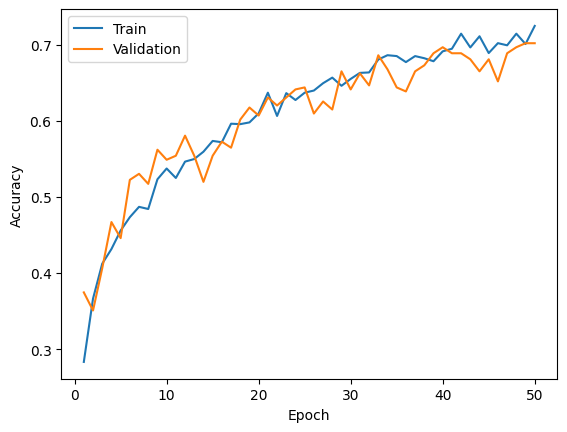

In [31]:
if 'final_history' in globals():
    import matplotlib.pyplot as plt
    epochs = range(1, len(final_history['train_accuracy']) + 1)
    plt.plot(epochs, final_history['train_accuracy'], label='Train')
    plt.plot(epochs, final_history['val_accuracy'], label='Validation')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
else:
    print("I need to finish the 50-epoch run first.")


## 11. Transfer learning — seed 1
I can train VGG16, ResNet50, and MobileNetV2 with the shared setup. These runs are separate from my Custom CNN.


In [32]:
from src.transfer_learning import run_transfer_learning

RUN_TRANSFER_MODELS = False  # I enable this after the Custom CNN run.

if RUN_TRANSFER_MODELS:
    import shutil
    for name in ['vgg16', 'resnet50', 'mobilenetv2']:
        set_seed(TRAINING_SEED)
        transfer_train_loader, transfer_val_loader, _ = create_dataloaders(
            SPLIT_CSV, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
            training_seed=TRAINING_SEED,
        )
        print("Training", name, "with seed", TRAINING_SEED)
        tl_model, stage1_history, stage2_history = run_transfer_learning(
            model_name=name,
            train_loader=transfer_train_loader,
            val_loader=transfer_val_loader,
            device=device,
            training_seed=TRAINING_SEED,
        )
        # The shared function writes to saved_models/ in the current working directory.
        target = CHECKPOINT_DIR / f'Seed_{TRAINING_SEED}'
        target.mkdir(parents=True, exist_ok=True)
        for stage in (1, 2):
            source = Path('saved_models') / f'{name}_seed{TRAINING_SEED}_stage{stage}.pth'
            shutil.copy2(source, target / source.name)
        print(name, "best fine-tuning val accuracy:", max(stage2_history['val_accuracy']))
else:
    print("I have not started my transfer-learning models yet.")


I have not started my transfer-learning models yet.
